# 07 — Mô phỏng giá trị kinh doanh và phân khúc (Task 10)

Ghép hai model đã đóng băng: `p_churn` đã hiệu chỉnh (Task 6) và `CLV_giữ_được` (Task 9). Câu hỏi: **phát voucher cho ai, và lợi nhuận tăng bao nhiêu so với phát đại trà?**

Lợi nhuận kỳ vọng khi phát voucher cho khách *i*:

`net_i = p_i × s × (K_i − δ_i) − (1 − p_i) × δ_i`, với `p` = `p_churn`, `K` = `CLV_giữ_được`, `s` = tỷ lệ cứu được nhờ voucher (chưa đo được → chạy độ nhạy 5–30%), `δ_i = mức giảm × avg_order_value_i` là chi phí voucher khi khách nhận và mua.

Đây là dạng từng khách của công thức lợi nhuận chiến dịch của Neslin et al. (2006), như được trình bày trong Verbeke et al. (2012): `Π = Nα[βγ(CLV − c − δ) + β(1−γ)(−c) + (1−β)(−c−δ)] − A`, với β → `p`, γ → `s`, CLV → `K`, δ → `δ_i`, chi phí liên hệ `c` = 0 và chi phí cố định `A` = 0. Chi phí `δ` chỉ phát sinh khi khách mua: khách vốn không churn (xác suất `1 − p`) đều dùng voucher, khách churn được cứu (xác suất `p·s`) cũng dùng, còn khách churn không được cứu thì không mua nên không tốn chi phí. Điểm khác công thức gốc: dùng giá trị `K_i`, `δ_i` riêng của từng khách thay cho giá trị trung bình. (Bản đầu của notebook này tính chi phí `δ_i` cho mọi khách nhận voucher, cao hơn công thức gốc; đã sửa theo dạng Neslin.)

Hòa vốn của khách *i*: `net_i > 0` ⇔ `s > s*_i = (1 − p_i) δ_i / (p_i (K_i − δ_i))` (chỉ có nghĩa khi `K_i > δ_i`; ngược lại voucher lỗ ở mọi `s`).

**Quy tắc chống nhìn trước:** ngưỡng tối ưu và ranh giới ma trận chọn trên **validation 2021-01**, rồi áp nguyên cho **test 2022-01**.

In [1]:
import sys; sys.path.insert(0, "../src")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import viz, churn_model, clv_model
from churn_data import load_churn_sets
from features import CATEGORICAL, build_snapshot
from clean import clean_tables
from to_parquet import load_tables
from config import TEST_CUTOFF

TRAIN, va = load_churn_sets()
cm, clv = churn_model.fit_final(), clv_model.fit_final()
te = build_snapshot(clean_tables(load_tables()), TEST_CUTOFF)
for c in CATEGORICAL:
    te[c] = pd.Categorical(te[c].astype(str).where(te[c].notna()), categories=TRAIN[c].cat.categories)

# mức giảm thực tế của dòng hàng có khuyến mãi (trung vị) -> chi phí voucher
oi = pd.read_parquet("../data/interim/order_items.parquet"); m = oi.promo_id.notna()
D = float((oi.discount_amount / (oi.quantity * oi.unit_price))[m].median())
print(f"mức giảm trung vị của dòng có khuyến mãi: {D:.1%}")

def prep(d):
    d = d.copy()
    d["p"] = cm.predict_proba(d)
    d["K"] = clv.predict(d)                    # CLV_giữ_được (lợi nhuận giá gốc, nếu khách quay lại)
    d["cost"] = D * d.avg_order_value
    d["score"] = d.p * d.K                     # p_churn × CLV
    return d
va, te = prep(va), prep(te)
S = 0.10   # tỷ lệ cứu mặc định
print("validation:", len(va), "| test:", len(te), "| p_churn TB test:", te.p.mean().round(3), "| churn thực tế test:", te.churn.mean().round(3))
print(te[["K", "cost", "score"]].describe().round(0))

mức giảm trung vị của dòng có khuyến mãi: 12.0%


validation: 52771 | test: 45880 | p_churn TB test: 0.65 | churn thực tế test: 0.648
             K     cost    score
count  45880.0  45880.0  45880.0
mean    4049.0   2960.0   2461.0
std      913.0   1460.0    426.0
min     2123.0     53.0    712.0
25%     3350.0   2108.0   2240.0
50%     3849.0   2788.0   2541.0
75%     4557.0   3548.0   2735.0
max    12293.0  22266.0   8676.0


## 1. Chiến lược, cùng ngân sách

Quy tắc tối ưu có chi phí: phát cho khách có `net_i > 0` (không cần ngưỡng học). Để so sánh công bằng, 4 chiến lược còn lại phát cho **đúng số khách** mà quy tắc `net > 0` chọn trên validation (tỷ lệ `f(s)`), chỉ khác cách xếp hạng: ngẫu nhiên (trung bình 200 lần bốc) / theo `p_churn` / theo `p_churn × CLV`. Nếu `f(s) = 0` thì không nên phát cho ai.

Lưới `s` gồm 5–30% (khoảng hợp lý theo kế hoạch) và 50–100% (**ngoài khoảng hợp lý**, chỉ để tìm điểm hòa vốn).

In [2]:
def net(d, s):
    """Neslin et al. (2006), từng khách, c = 0, A = 0: p·s·(K − δ) − (1 − p)·δ."""
    return d.p * s * (d.K - d.cost) - (1 - d.p) * d.cost

def strategies(d, f, s, seed=0):
    """Lợi nhuận kỳ vọng của từng chiến lược trên d; chiến lược xếp hạng phát cho đúng top f của d."""
    n = net(d, s); k = int(round(f * len(d))); r = np.random.RandomState(seed)
    top = lambda key: n.values[np.argsort(-d[key].values, kind="stable")[:k]].sum()
    return {"Không làm gì": 0.0, "Phát cho tất cả": n.sum(),
            "Phát ngẫu nhiên": np.mean([n.values[r.permutation(len(d))[:k]].sum() for _ in range(200)]),
            "Theo p_churn": top("p"), "Theo p_churn × CLV": top("score"), "Theo net > 0 (có chi phí)": n[n > 0].sum()}

S_GRID = [.05, .10, .20, .30, .50, .75, 1.0]
rows = []
for s_ in S_GRID:
    f = (net(va, s_) > 0).mean()
    r_ = strategies(te, f, s_); rows.append({"s": f"{s_:.0%}", "f_validation": f, "f_test": (net(te, s_) > 0).mean(), **r_})
sens = pd.DataFrame(rows).set_index("s")
print("s hòa vốn của phát đại trà (Σ(1−p)δ / Σp(K−δ)):", round(((1 - te.p) * te.cost).sum() / (te.p * (te.K - te.cost)).sum(), 3))
sens.round(3)

s hòa vốn của phát đại trà (Σ(1−p)δ / Σp(K−δ)): 1.937


,f_validation,f_test,Không làm gì,Phát cho tất cả,Phát ngẫu nhiên,Theo p_churn,Theo p_churn × CLV,Theo net > 0 (có chi phí)
s,,,,,,,,
5%,0.054,0.044,0.0,-4.612150e+07,-2494819.202,-394100.459,-819006.406,1.194677e+05
10%,0.088,0.071,0.0,-4.489971e+07,-3945593.828,-733087.790,-1185170.454,4.008133e+05
20%,0.142,0.116,0.0,-4.245613e+07,-6029647.155,-1240506.870,-2199379.670,1.219133e+06
30%,0.186,0.154,0.0,-4.001255e+07,-7441695.123,-1954602.171,-3065559.076,2.297324e+06
50%,0.256,0.219,0.0,-3.512539e+07,-8995210.848,-3054728.512,-4146279.493,5.047771e+06
75%,0.327,0.293,0.0,-2.901644e+07,-9500896.022,-3815574.685,-4771695.034,9.366903e+06
100%,0.390,0.361,0.0,-2.290749e+07,-8949100.345,-3699146.345,-4524031.989,1.454472e+07


Một ngân sách cố định 20% khách, để thấy phần đóng góp riêng của CLV (chiến lược 4 so với 5) khi bỏ qua chi phí tối ưu:

In [3]:
fx = pd.DataFrame({f"s = {s_:.0%}, phát cho 20% khách": strategies(te, .2, s_) for s_ in (.30, 1.0)})
fx.round(0)

,"s = 30%, phát cho 20% khách","s = 100%, phát cho 20% khách"
Không làm gì,0.0,0.0
Phát cho tất cả,-40012548.0,-22907492.0
Phát ngẫu nhiên,-8002455.0,-4582116.0
Theo p_churn,-2135111.0,-1289088.0
Theo p_churn × CLV,-3343203.0,-3015245.0
Theo net > 0 (có chi phí),2297324.0,14544718.0


## 2. Đường lợi nhuận theo tỷ lệ khách được phát (test)

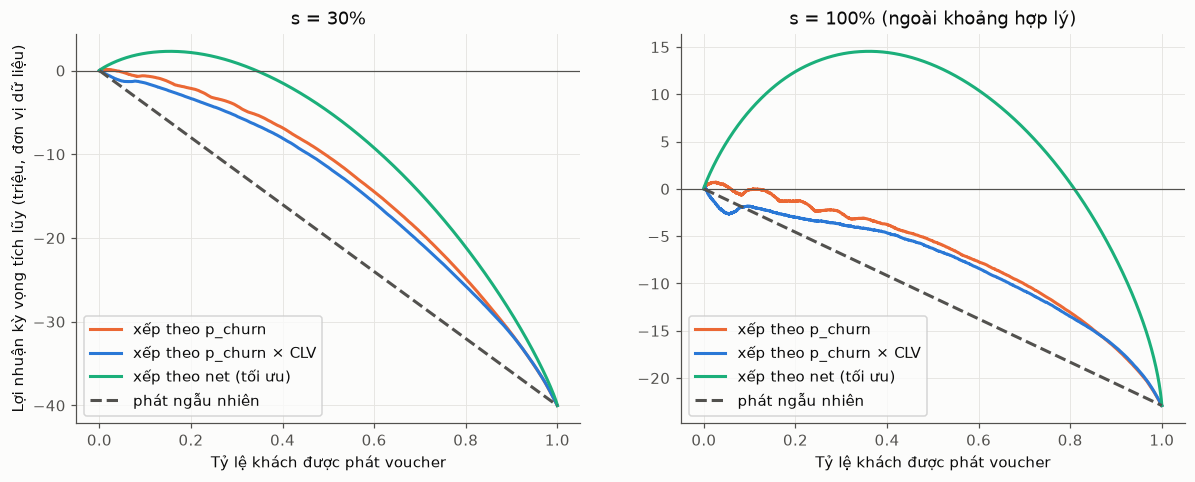

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
x = np.arange(1, len(te) + 1) / len(te)
for ax, s_ in zip(axes, (.30, 1.0)):
    for key, lab, col in [("p", "xếp theo p_churn", viz.C[1]), ("score", "xếp theo p_churn × CLV", viz.C[0])]:
        o = te.sort_values(key, ascending=False); ax.plot(x, net(o, s_).cumsum().values / 1e6, color=col, label=lab)
    o = te.assign(n=net(te, s_)).sort_values("n", ascending=False); ax.plot(x, o.n.cumsum().values / 1e6, color=viz.C[2], label="xếp theo net (tối ưu)")
    ax.plot([0, 1], [0, net(te, s_).sum() / 1e6], color=viz.INK2, ls="--", label="phát ngẫu nhiên"); ax.axhline(0, color=viz.INK2, lw=.8)
    ax.set(xlabel="Tỷ lệ khách được phát voucher", title=f"s = {s_:.0%}" + (" (ngoài khoảng hợp lý)" if s_ > .3 else "")); ax.legend()
axes[0].set_ylabel("Lợi nhuận kỳ vọng tích lũy (triệu, đơn vị dữ liệu)")
viz.save(fig, "08_profit_curve"); plt.show()

## 3. Tỷ lệ cứu hòa vốn của từng khách

`s*_i = (1 − p_i) δ_i / (p_i (K_i − δ_i))`: voucher chỉ có lãi với khách *i* nếu thật sự cứu được hơn `s*_i` số khách như họ. Khi `K_i ≤ δ_i` voucher lỗ ở mọi `s` (`s*` = vô cùng).

s* hòa vốn của khách (test): phân vị 5% / 25% / trung vị / 75%: [0.06, 0.61, 1.63, 5.56]
{'s* <= 30%': '15.4% khách', 's* <= 50%': '21.9% khách', 's* <= 100%': '36.1% khách'}
lợi nhuận/đơn trên AOV: 0.113 | mức giảm: 0.12


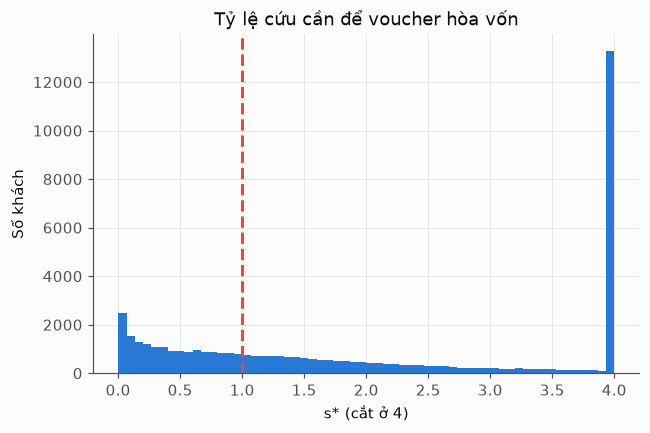

In [5]:
sb = ((1 - te.p) * te.cost / (te.p * (te.K - te.cost))).where(te.K > te.cost, np.inf)
print("s* hòa vốn của khách (test): phân vị 5% / 25% / trung vị / 75%:", sb.quantile([.05, .25, .5, .75]).round(2).tolist())
print({f"s* <= {t:.0%}": f"{(sb <= t).mean():.1%} khách" for t in (.3, .5, 1.0)})
print("lợi nhuận/đơn trên AOV:", round((te.K / clv.expected_orders(te)).mean() / te.avg_order_value.mean(), 3), "| mức giảm:", round(D, 3))
fig, ax = plt.subplots(figsize=(6.4, 4)); ax.hist(sb.clip(upper=4), bins=60, color=viz.C[0]); ax.axvline(1, color=viz.C[7], ls="--")
ax.set(xlabel="s* (cắt ở 4)", ylabel="Số khách", title="Tỷ lệ cứu cần để voucher hòa vốn"); viz.save(fig, "08_breakeven_s"); plt.show()

## 4. Ma trận phân khúc 2×2

Ranh giới (cố định theo logic hòa vốn, không tinh chỉnh trên test):
- **p_churn cao** ⇔ `p_churn` ≥ `p_churn` trung bình validation.
- **CLV cao** ⇔ `CLV_giữ_được` ≥ chi phí một voucher của chính khách đó. Đây là điều kiện *cần*: nếu CLV < chi phí thì voucher lỗ ngay cả khi cứu được 100% khách. Điều kiện *đủ* là `s > s*` (mục 3), nên mỗi ô báo thêm tỷ lệ khách có lãi ở s = 30% và 50%.

Mức voucher trong ô "Giữ ngay" bị chặn sao cho `net_i ≥ 0`: `δ_max = s p K / (1 − p + s p)`, mức giảm tối đa `= min(mức giảm trung vị, δ_max / avg_order_value)`, tính ở s = 30% (mức cao nhất trong khoảng hợp lý).

In [6]:
p_cut = va.p.mean(); S_CAP = .30
te["segment"] = np.select([(te.p >= p_cut) & (te.K >= te.cost), (te.p >= p_cut), (te.K >= te.cost)], ["Giữ ngay", "Không chi tiền", "Chăm sóc, không giảm giá"], "Để tự nhiên")
te["max_discount"] = np.minimum(D, S_CAP * te.p * te.K / (1 - te.p + S_CAP * te.p) / te.avg_order_value)
g = te.groupby("segment")
mat = pd.DataFrame({"khách": g.size(), "%_khách": g.size() / len(te), "p_churn_TB": g.p.mean(), "churn_thực_tế": g.churn.mean(),
                    "CLV_giữ_được_TB": g.K.mean(), "lợi_nhuận_thực_tế_tổng": g.future_gross_profit.sum(), "lợi_nhuận_thực_tế_TB": g.future_gross_profit.mean(),
                    "%_có_lãi_s30": g.apply(lambda d: (net(d, .3) > 0).mean()), "%_có_lãi_s50": g.apply(lambda d: (net(d, .5) > 0).mean()),
                    # quy tắc của hệ thống: ô Giữ ngay và net > 0 ở s = 30% (tasks/voucher-rule-plan.md)
                    "nhận_voucher": g.apply(lambda d: int((net(d, .3) > 0).sum()) if d.name == "Giữ ngay" else 0)})
mat["%_lợi_nhuận_thực_tế"] = mat.lợi_nhuận_thực_tế_tổng / te.future_gross_profit.sum()
gi = te[te.segment.str.startswith("Giữ")]
print(f"p_cut = {p_cut:.3f}")
print("mức giảm tối đa ô Giữ ngay (trung vị / TB / tối đa):", gi.max_discount.agg(["median", "mean", "max"]).round(3).to_dict() if len(gi) else "ô rỗng")
mat.round(3)

p_cut = 0.675
mức giảm tối đa ô Giữ ngay (trung vị / TB / tối đa): {'median': 0.113, 'mean': 0.101, 'max': 0.12}


,khách,%_khách,p_churn_TB,churn_thực_tế,CLV_giữ_được_TB,lợi_nhuận_thực_tế_tổng,lợi_nhuận_thực_tế_TB,%_có_lãi_s30,%_có_lãi_s50,nhận_voucher,%_lợi_nhuận_thực_tế
segment,,,,,,,,,,,
"Chăm sóc, không giảm giá",22251,0.485,0.479,0.476,4739.578,5.069120e+07,2278.154,0.010,0.048,0,0.793
Giữ ngay,15018,0.327,0.818,0.816,3360.723,8.151724e+06,542.797,0.455,0.600,6839,0.128
Không chi tiền,7059,0.154,0.839,0.843,3333.415,2.982658e+06,422.533,0.000,0.000,0,0.047
Để tự nhiên,1552,0.034,0.598,0.607,4067.809,2.067431e+06,1332.107,0.000,0.000,0,0.032


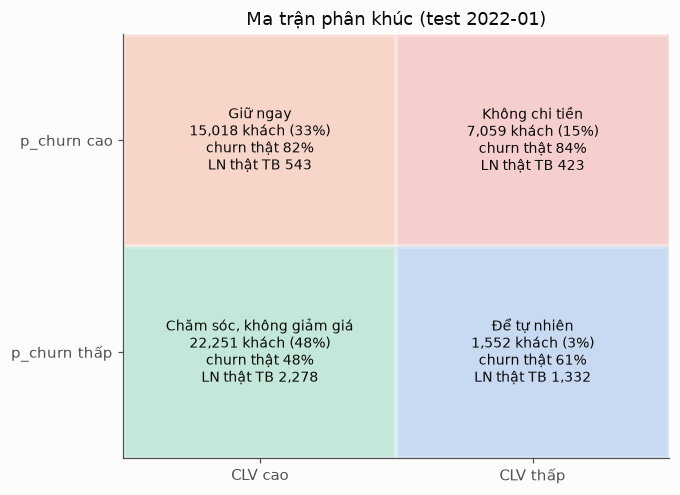

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 5)); ax.grid(False)
cells = {"Giữ ngay": (0, 1, viz.C[1]), "Không chi tiền": (1, 1, viz.C[7]), "Chăm sóc, không giảm giá": (0, 0, viz.C[2]), "Để tự nhiên": (1, 0, viz.C[0])}
for name, (cx, cy, col) in cells.items():
    ax.add_patch(plt.Rectangle((cx, cy), 1, 1, fc=col, alpha=.25, ec="white", lw=3))
    if name in mat.index:
        r_ = mat.loc[name]
        ax.text(cx + .5, cy + .5, f"{name}\n{int(r_.khách):,} khách ({r_['%_khách']:.0%})\nchurn thật {r_.churn_thực_tế:.0%}\nLN thật TB {r_.lợi_nhuận_thực_tế_TB:,.0f}", ha="center", va="center", fontsize=9)
    else: ax.text(cx + .5, cy + .5, f"{name}\n(rỗng)", ha="center", va="center", fontsize=9)
ax.set(xlim=(0, 2), ylim=(0, 2), xticks=[.5, 1.5], yticks=[.5, 1.5], xticklabels=["CLV cao", "CLV thấp"], yticklabels=["p_churn thấp", "p_churn cao"], title=f"Ma trận phân khúc (test 2022-01)")
viz.save(fig, "08_segment_matrix"); plt.show()

## 5. Số dùng cho kết luận

In [8]:
a = te[te.p >= p_cut]; big = te.nlargest(int(.2 * len(te)), "score")
print(f"top 20% theo p×CLV: churn thực tế {big.churn.mean():.1%} (toàn bộ {te.churn.mean():.1%}), bắt {big.churn.sum() / te.churn.sum():.1%} số churn, "
      f"chiếm {big.future_gross_profit.sum() / te.future_gross_profit.sum():.1%} lợi nhuận thực tế")
print(f"phát đại trà ở s=30%: net {net(te, .3).sum():,.0f} | chỉ phát cho net>0: {net(te, .3)[net(te, .3) > 0].sum():,.0f} ({(net(te, .3) > 0).mean():.1%} khách)")
print(f"churn thực tế: p_churn cao {a.churn.mean():.1%} | thấp {te[te.p < p_cut].churn.mean():.1%}")

top 20% theo p×CLV: churn thực tế 88.4% (toàn bộ 64.8%), bắt 27.3% số churn, chiếm 5.1% lợi nhuận thực tế
phát đại trà ở s=30%: net -40,012,548 | chỉ phát cho net>0: 2,297,324 (15.4% khách)
churn thực tế: p_churn cao 82.4% | thấp 48.4%


In [9]:
# vì sao phát đại trà lỗ, và vì sao thêm CLV vào xếp hạng làm tệ hơn
for s_ in (.05, .10, .20, .30, 1.0):
    a_, b_ = ((1 - te.p) * te.cost).sum(), (te.p * s_ * te.cost).sum()
    print(f"s = {s_:.0%}: chi phí voucher rơi vào khách không churn {a_ / (a_ + b_):.1%}")
print("Spearman CLV_giữ_được ~ chi phí voucher:", round(te.K.corr(te.cost, "spearman"), 3))
k = int(round((net(va, .3) > 0).mean() * len(te)))   # cùng số khách với mục 1 ở s = 30%
pd.DataFrame({f"top {k / len(te):.1%} theo {key}": te.nlargest(k, key).assign(K_trừ_chi_phí=lambda d: d.K - d.cost)[["cost", "K", "p", "K_trừ_chi_phí"]].mean()
              for key in ("p", "score")}).T.round(3)

s = 5%: chi phí voucher rơi vào khách không churn 91.5%
s = 10%: chi phí voucher rơi vào khách không churn 84.3%
s = 20%: chi phí voucher rơi vào khách không churn 72.8%
s = 30%: chi phí voucher rơi vào khách không churn 64.1%
s = 100%: chi phí voucher rơi vào khách không churn 34.9%
Spearman CLV_giữ_được ~ chi phí voucher: 0.136


,cost,K,p,K_trừ_chi_phí
top 18.6% theo p,3024.377,3147.213,0.913,122.836
top 18.6% theo score,3287.892,3344.993,0.886,57.101


## Kết luận (test 2022-01, ngưỡng và ranh giới không chỉnh theo test)

1. **Voucher giảm theo % đơn không có lãi khi phát đại trà ở mặt bằng dữ liệu này.** Biên gộp chỉ ~11% giá trị đơn, trong khi voucher 12% ăn hết lợi nhuận một đơn. Phát cho tất cả lỗ ở mọi `s` từ 5% đến 100% (−46,1 triệu ở 5%, −40,0 triệu ở 30%, −22,9 triệu ở 100%); `s` hòa vốn của phát đại trà là 194%, tức không đạt được. Ở `s` = 5–30%, 64–92% chi phí voucher rơi vào khách vốn không churn (mục 5).
2. **Xếp hạng không tính chi phí vẫn lỗ, nhưng tốt hơn ngẫu nhiên.** Cùng số khách với quy tắc `net > 0` chọn trên validation (18,6% khách ở `s` = 30%): ngẫu nhiên −7,4 triệu, theo `p_churn` −1,95 triệu, theo `p_churn × CLV` −3,07 triệu. Biết rủi ro giúp, nhưng thêm CLV **không** giúp thêm mà làm tệ hơn chỉ dùng `p_churn`, vì so với nhóm chọn theo `p_churn`, nhóm chọn theo `p_churn × CLV` có chi phí voucher cao hơn ~9% trong khi CLV giữ được chỉ cao hơn ~6% và `p_churn` thấp hơn, nên `K − δ` trung bình mỗi khách giảm từ 123 xuống 57 (mục 5). Lý do không phải khách CLV cao mua đơn lớn: trên toàn tập, CLV và chi phí voucher gần như không tương quan (Spearman 0,14). Nhất quán với Task 9 (xếp hạng lợi nhuận kỳ vọng chủ yếu nhờ `p_churn`) và với Ascarza (2018): xếp theo rủi ro chưa đủ.
3. **Quy tắc đúng là `net_i > 0` (có chi phí, dạng Neslin).** Là chiến lược duy nhất có lãi: +0,12 triệu ở `s` = 5% (4,4% khách), +0,40 triệu ở 10% (7,1%), +1,22 triệu ở 20% (11,6%), +2,30 triệu ở 30% (15,4%), +14,5 triệu ở 100% (36,1%). Tỷ lệ khách được chọn trên validation (18,6% ở `s` = 30%) gần với test (15,4%) nên khá ổn định.
4. **Tỷ lệ cứu hòa vốn của khách:** trung vị `s*` = 1,63; 15,4% khách có `s*` ≤ 30%, 21,9% ≤ 50%, 36,1% ≤ 100%. Đa số khách không bao giờ đáng nhận voucher %, dù cứu được 100%.
5. **`p_churn` vẫn phân tách tốt trên test:** p cao → churn thật 82,4%, p thấp → 48,4%; top 20% theo `p×CLV` churn thật 88,4%.
6. **Ma trận phân khúc.** Ô "Giữ ngay" có 32,7% khách; trong đó 45,5% có lãi ở `s` = 30% và 60% ở `s` = 50%, mức giảm tối đa hợp lý (để `net ≥ 0` ở `s` = 30%) có trung vị 11,3%. Ô "Chăm sóc, không giảm giá" (48,5% khách, p thấp) chiếm 79% lợi nhuận thực tế và chỉ 1,0% khách có lãi nếu phát voucher: đây là nhóm cần bảo vệ, không nên phát giảm giá.

**Đề xuất kinh doanh (chưa kiểm chứng được loại ưu đãi vì dữ liệu không có phản hồi theo từng loại):** chỉ phát voucher cho nhóm `net > 0` (khoảng 15% khách ở `s` = 30%, càng thấp nếu `s` thật thấp), với mức giảm không vượt mức hòa vốn của khách; với phần còn lại dùng ưu đãi chi phí thấp (quà tặng, miễn phí giao hàng, điểm thưởng); đo `s` thật bằng nhóm đối chứng trên web (Giai đoạn B) trước khi mở rộng.

**Hạn chế:** `s` không đo được từ dữ liệu (đã chạy độ nhạy) và giả định đồng nhất giữa các khách (Ascarza, 2018: mức đáp ứng khác nhau theo khách); giả định mọi khách mua đều dùng voucher trên 1 đơn; mức giảm 12% lấy từ trung vị dòng hàng có khuyến mãi (kế hoạch ghi 16,5%, số này không tái lập được từ `order_items`); chi phí liên hệ và chi phí cố định đặt bằng 0; CLV dùng lợi nhuận giá gốc nên lệch mức tổng ~0,73 ở test (Task 9); đơn vị tiền không xác định (Task 1) nên chỉ so sánh tương đối.

**Ghi chú sửa đổi (2026-11-02):** bản đầu của notebook tính chi phí voucher cho mọi khách nhận (`net = p·s·K − δ`), cao hơn công thức gốc của Neslin et al. (2006) vì khách churn không được cứu thì không mua nên không tốn voucher. Bản này dùng đúng dạng Neslin; kết luận "phát đại trà lỗ" giữ nguyên, nhưng "xếp hạng theo p hay p×CLV kém ngẫu nhiên" **không còn đúng**, và tỷ lệ khách đáng phát tăng từ 3,3% lên 15,4% ở `s` = 30%.